# Exploratory Data Analysis (EDA)

## 1. Setup

### 1.1 Imports

In [29]:
from haversine import haversine
import matplotlib.pyplot as plt
import pandas as pd
import ast

Matplotlib is building the font cache; this may take a moment.


In [30]:
def compute_distance(polyline) -> float:
    """
    Compute the total distance along a polyline.

    Args:
        polyline: A sequence of coordinate points.

    Returns:
        float: The total distance along the polyline. Returns 0 if the
        polyline contains fewer than two points.
    """
    if len(polyline) < 2:
        return 0

    distance = 0
    for i in range(len(polyline) - 1):
        distance += haversine(polyline[i], polyline[i + 1])

    return distance

### 1.2 Helper Functions

### 1.3 Load Dataset

In [31]:
DATA_PATH = "data/porto.csv"
df = pd.read_csv(DATA_PATH)

## 2. Dataset Overview

In [15]:
print("Shape:", df.shape)

Shape: (1710670, 9)


In [21]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str),
    "Non-null values": df.notna().sum(),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})

display(column_info)

,Column,Data type,Non-null values,Missing values,Unique values
TRIP_ID,TRIP_ID,int64,1710670,0,1710589
CALL_TYPE,CALL_TYPE,str,1710670,0,3
ORIGIN_CALL,ORIGIN_CALL,float64,364770,1345900,57105
ORIGIN_STAND,ORIGIN_STAND,float64,806579,904091,63
TAXI_ID,TAXI_ID,int64,1710670,0,448
TIMESTAMP,TIMESTAMP,int64,1710670,0,1655366
DAY_TYPE,DAY_TYPE,str,1710670,0,1
MISSING_DATA,MISSING_DATA,bool,1710670,0,2
POLYLINE,POLYLINE,str,1710670,0,1703650


In [17]:
display(df.head())

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
0,1372636858620000589,C,NaN,NaN,20000589,1372636858,A,False,"[[-8.618643,41.141412],[-8.618499,41.141376],[..."
1,1372637303620000596,B,NaN,7.0,20000596,1372637303,A,False,"[[-8.639847,41.159826],[-8.640351,41.159871],[..."
2,1372636951620000320,C,NaN,NaN,20000320,1372636951,A,False,"[[-8.612964,41.140359],[-8.613378,41.14035],[-..."
3,1372636854620000520,C,NaN,NaN,20000520,1372636854,A,False,"[[-8.574678,41.151951],[-8.574705,41.151942],[..."
4,1372637091620000337,C,NaN,NaN,20000337,1372637091,A,False,"[[-8.645994,41.18049],[-8.645949,41.180517],[-..."


In [18]:
display(df.describe(include="all"))

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
count,1.710670e+06,1710670,364770.000000,806579.000000,1.710670e+06,1.710670e+06,1710670,1710670,1710670
unique,NaN,3,NaN,NaN,NaN,NaN,1,2,1703650
top,NaN,B,NaN,NaN,NaN,NaN,A,False,[]
freq,NaN,817881,NaN,NaN,NaN,NaN,1710670,1710660,5901
mean,1.388622e+18,NaN,24490.363018,30.272381,2.000035e+07,1.388622e+09,NaN,NaN,NaN
std,9.180944e+15,NaN,19624.290043,17.747840,2.112405e+02,9.180944e+06,NaN,NaN,NaN
min,1.372637e+18,NaN,2001.000000,1.000000,2.000000e+07,1.372637e+09,NaN,NaN,NaN
25%,1.380731e+18,NaN,6593.000000,15.000000,2.000017e+07,1.380731e+09,NaN,NaN,NaN
50%,1.388493e+18,NaN,18755.000000,27.000000,2.000034e+07,1.388493e+09,NaN,NaN,NaN
75%,1.396750e+18,NaN,40808.000000,49.000000,2.000052e+07,1.396750e+09,NaN,NaN,NaN


## 2. Data Preparation

In [44]:
df["DATETIME"] = pd.to_datetime(df["TIMESTAMP"], unit="s")
df["DATE"] = df["DATETIME"].dt.date
df["POLYLINE"] = df["POLYLINE"].apply(ast.literal_eval)
df["GPS_POINTS"] = df["POLYLINE"].apply(len)
df["DURATION"] = (df["GPS_POINTS"] - 1) * 15
df["DISTANCE"] = df["POLYLINE"].apply(compute_distance)

## 4. Distribution of Call Types

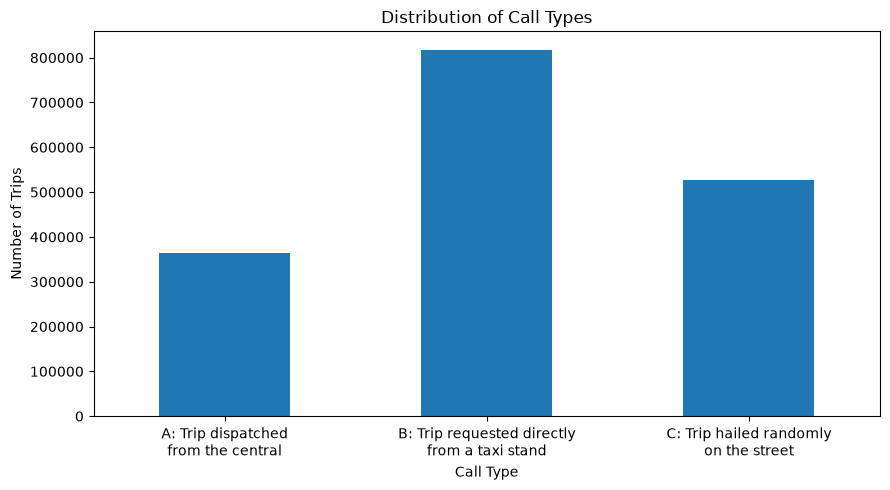

In [70]:
call_type_names = {
    "A": "A: Trip dispatched\nfrom the central",
    "B": "B: Trip requested directly\nfrom a taxi stand",
    "C": "C: Trip hailed randomly\non the street"
}

call_type_counts = (
    df["CALL_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

call_type_counts.index = call_type_counts.index.map(call_type_names)

ax = call_type_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Call Types",
    xlabel="Call Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

## 3. Distribution of Day Types

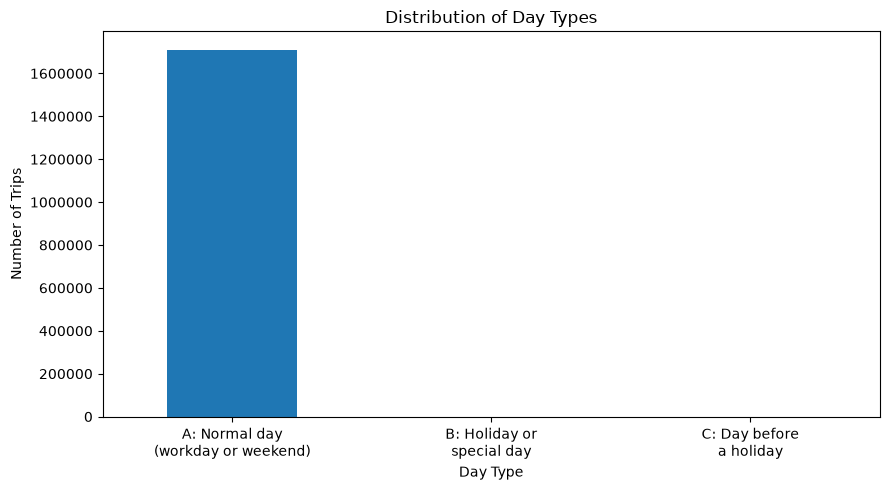

In [71]:
daytype_names = {
    "A": "A: Normal day\n(workday or weekend)",
    "B": "B: Holiday or\nspecial day",
    "C": "C: Day before\na holiday"
}

daytype_counts = (
    df["DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

daytype_counts.index = daytype_counts.index.map(daytype_names)

ax = daytype_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Day Types",
    xlabel="Day Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

## 4. Number of Trips per Hour, Weekday and Month

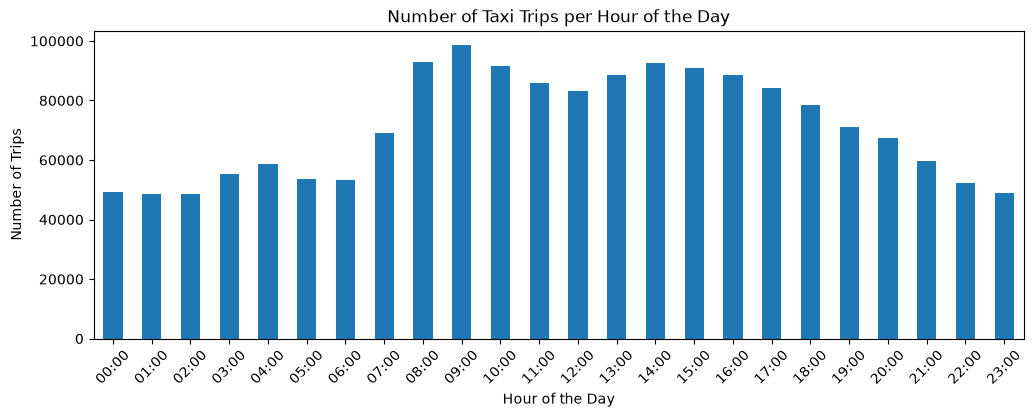

In [57]:
trips_per_hour = (
    df.groupby(df["DATETIME"].dt.hour)
      .size()
      .reindex(range(24), fill_value=0)
)

ax = trips_per_hour.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Taxi Trips per Hour of the Day",
    xlabel="Hour of the Day",
    ylabel="Number of Trips"
)

ax.set_xticklabels(
    [f"{hour:02d}:00" for hour in range(24)],
    rotation=45
);

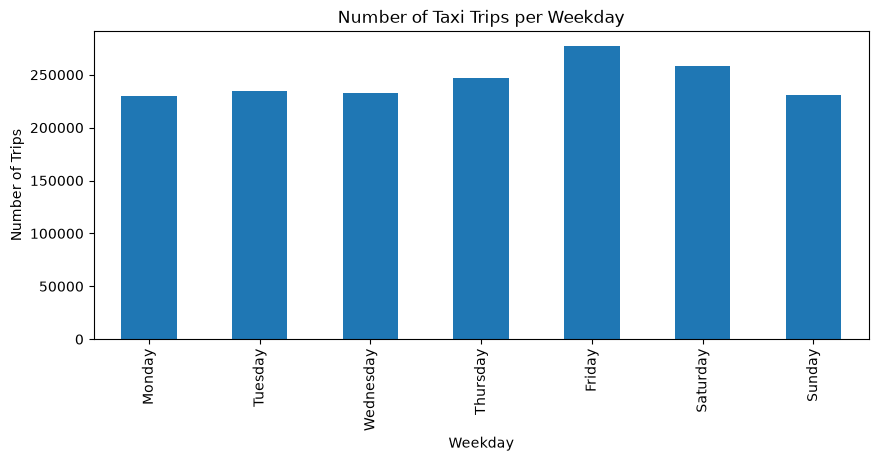

In [47]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

trips_per_weekday = (
    df.groupby(df["DATETIME"].dt.day_name())
      .size()
      .reindex(weekday_order)
)

trips_per_weekday.plot(
    kind="bar",
    figsize=(10, 4),
    title="Number of Taxi Trips per Weekday",
    xlabel="Weekday",
    ylabel="Number of Trips"
);

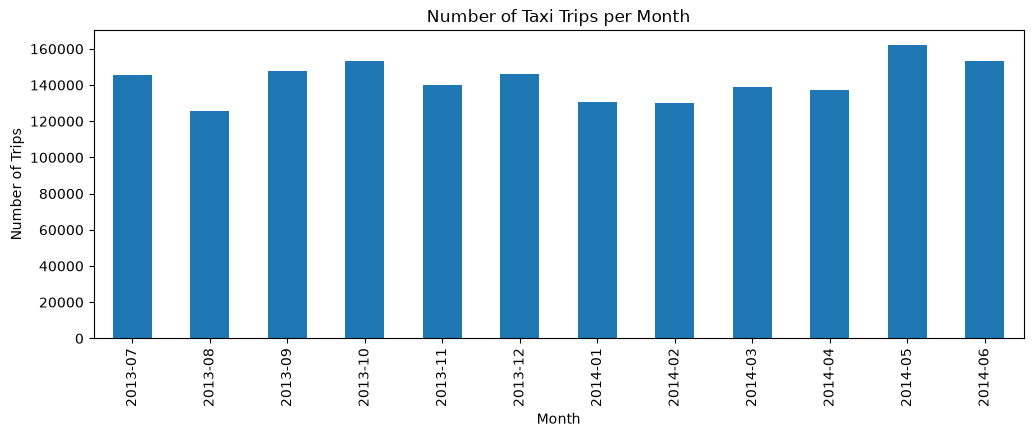

In [48]:
trips_per_month = (
    df.groupby(df["DATETIME"].dt.to_period("M"))
      .size()
      .sort_index()
)

trips_per_month.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Taxi Trips per Month",
    xlabel="Month",
    ylabel="Number of Trips"
);

## 5. Distribution of GPS Points per Trip

Text(0, 0.5, 'Number of Trips (log scale)')

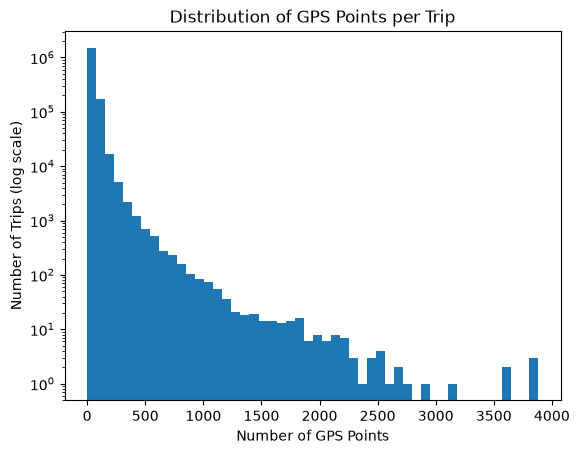

In [63]:
ax = df["GPS_POINTS"].plot(
    kind="hist",
    bins=50,
    title="Distribution of GPS Points per Trip",
    xlabel="Number of GPS Points"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")

## 6. Distribution of Trip Duration per Trip

Text(0, 0.5, 'Number of Trips (log scale)')

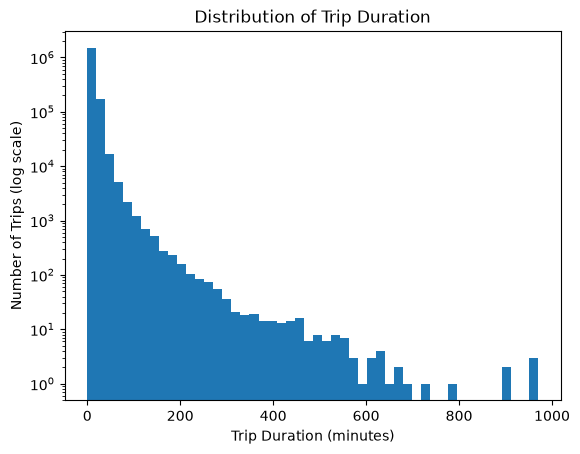

In [65]:
ax = (df["DURATION"] / 60).plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Duration",
    xlabel="Trip Duration (minutes)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")

## 7. Top 10 Most Active Taxi Drivers

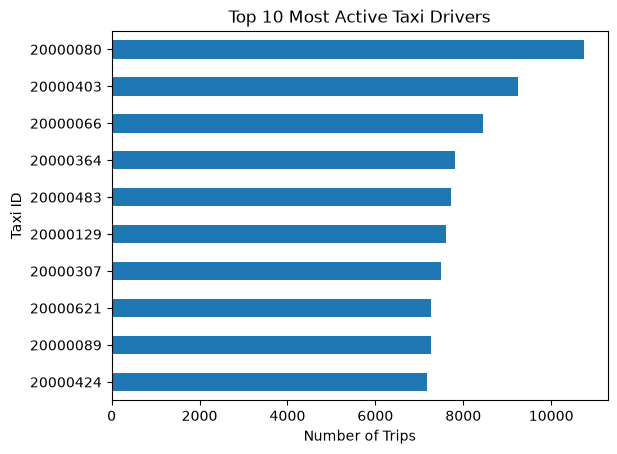

In [53]:
top_taxis = df["TAXI_ID"].value_counts().head(10)

top_taxis.sort_values().plot(
    kind="barh",
    title="Top 10 Most Active Taxi Drivers",
    xlabel="Number of Trips",
    ylabel="Taxi ID"
);

## 8. Number of Trips per Taxi

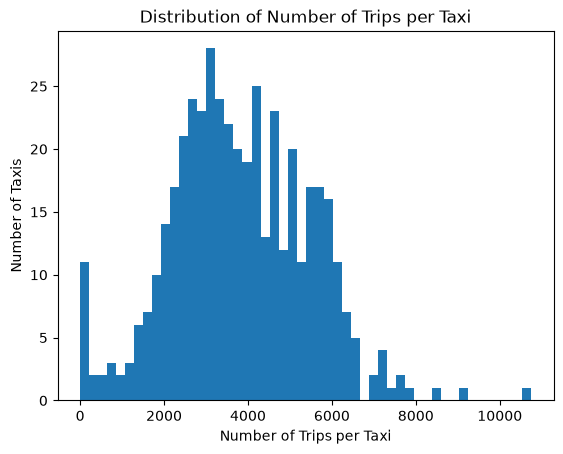

In [66]:
trips_per_taxi = df.groupby("TAXI_ID").size()

trips_per_taxi.plot(
    kind="hist",
    bins=50,
    title="Distribution of Number of Trips per Taxi",
    xlabel="Number of Trips per Taxi",
    ylabel="Number of Taxis"
);

## 9. Distribution of Trip Distance

Text(0, 0.5, 'Number of Trips (log scale)')

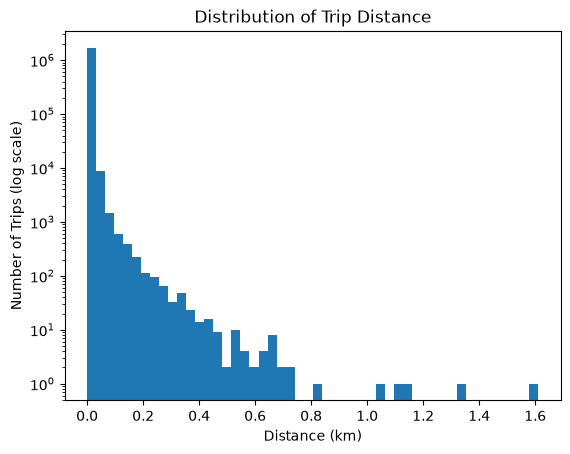

In [68]:
ax = (df["DISTANCE"] / 1000).plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Distance",
    xlabel="Distance (km)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")